ONLINE TRANSACTION FRAUD DETECTION

Python-Based Exploratory Data Analysis,
Fraud Pattern Analysis & Predictive Modeling


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.ensemble import RandomForestClassifier

In [3]:
df = pd.read_excel(r"C:\Users\OMAIR\Downloads\Online Fraud detection project.xlsx")

In [18]:
df.head()

,Transaction_ID,Customer_ID,Transaction_DateTime,Amount,Currency,Payment_Method,Merchant_Category,Transaction_Type,City,Country,...,Account_Age_Months,Transaction_Amount_Band,Velocity_Risk,Location_Risk,Login_Risk,Risk_Category,Anomaly_Flag,Card_Transaction_Flag,Data_Quality_Flag,Amount_Quality
0,TXN-038213,CUST-03213,2025-08-07 07:30:00,3860.68,INR,Debit Card,Fashion,Refund,Mumbai,India,...,72,Medium,Very Low,Very Low,Unknown,Medium,No,Yes,OK,Valid
1,TXN-039589,CUST-01089,2025-01-14 13:51:00,304.93,Unknown,Credit Card,Grocery,Subscription,Delhi,India,...,48,Very Low,Very Low,Very Low,Unknown,High,No,Yes,OK,Valid
2,TXN-024320,Unknown ID,2025-07-24 19:09:00,3150.77,INR,UPI,Grocery,Purchase,Ahmedabad,India,...,36,Medium,Very Low,Medium,Unknown,High,No,No,Needs Review,Valid
3,TXN-010921,CUST-00421,2025-03-03 14:58:00,1299.02,INR,Credit Card,Healthcare,Purchase,Lucknow,India,...,48,Low,Medium,Very Low,Unknown,Medium,No,Yes,OK,Valid
4,TXN-029994,CUST-01994,2025-07-23 04:54:00,393.28,INR,Unknown,Grocery,Subscription,Hyderabad,India,...,36,Very Low,Low,Very Low,Low,High,No,No,Needs Review,Valid


In [19]:
df.shape


(19697, 36)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19697 entries, 0 to 19696
Data columns (total 36 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Transaction_ID             19697 non-null  object        
 1   Customer_ID                19697 non-null  object        
 2   Transaction_DateTime       19697 non-null  datetime64[ns]
 3   Amount                     19697 non-null  float64       
 4   Currency                   19697 non-null  object        
 5   Payment_Method             19697 non-null  object        
 6   Merchant_Category          19697 non-null  object        
 7   Transaction_Type           19697 non-null  object        
 8   City                       19697 non-null  object        
 9   Country                    19697 non-null  object        
 10  Device_Type                19697 non-null  object        
 11  Browser                    19697 non-null  object        
 12  Tran

In [24]:
df.describe()

,Transaction_DateTime,Amount,Transactions_Last_24H,Distance_From_Home_KM,Failed_Login_Attempts,Account_Age_Years,Is_Fraud,Risk_Score,Transaction_Hour,Account_Age_Months
count,19697,19697.000000,19697.000000,19697.000000,19697.000000,19697.000000,19697.000000,19697.000000,19697.000000,19697.000000
mean,2025-07-02 16:43:26.004975360,2358.014664,1.994162,55.783693,0.504239,3.485708,0.033152,53.411511,11.573590,41.828502
min,2025-01-01 00:33:00,-150.000000,0.000000,0.000000,0.000000,1.000000,0.000000,18.680000,0.000000,12.000000
25%,2025-04-02 06:26:00,557.740000,1.000000,0.000000,0.000000,2.000000,0.000000,46.450000,6.000000,24.000000
50%,2025-07-03 14:56:00,1095.230000,2.000000,43.800000,0.000000,3.000000,0.000000,52.730000,12.000000,36.000000
75%,2025-10-01 20:49:00,2158.420000,3.000000,92.300000,1.000000,5.000000,0.000000,59.690000,18.000000,60.000000
max,2025-12-31 22:30:00,999999.990000,11.000000,298.800000,5.000000,6.000000,1.000000,100.000000,23.000000,72.000000
std,NaN,23689.932191,1.419559,55.179695,0.713180,1.702310,0.179039,10.193693,6.937656,20.427718


In [26]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df["Transaction_ID"].duplicated().sum()

np.int64(0)

In [29]:
df["Is_Fraud"].value_counts()

Is_Fraud
0    19044
1      653
Name: count, dtype: int64

In [30]:
df["Is_Fraud"].value_counts(normalize=True) * 100

Is_Fraud
0    96.684774
1     3.315226
Name: proportion, dtype: float64

In [31]:
fraud_summary = df.groupby("Is_Fraud").agg(
    Transactions=("Transaction_ID", "count"),
    Total_Amount=("Amount", "sum"),
    Average_Amount=("Amount", "mean"),
    Minimum_Amount=("Amount", "min"),
    Maximum_Amount=("Amount", "max")
)

fraud_summary

,Transactions,Total_Amount,Average_Amount,Minimum_Amount,Maximum_Amount
Is_Fraud,,,,,
0,19044,41279588.42,2167.590234,-150.00,999999.99
1,653,5166226.42,7911.525911,52.04,999999.99


In [33]:
df.groupby("Is_Fraud")["Amount"].agg(
    ["count", "mean", "median", "min", "max", "std"]
)

,count,mean,median,min,max,std
Is_Fraud,,,,,,
0,19044,2167.590234,1095.605,-150.00,999999.99,19266.085030
1,653,7911.525911,1087.440,52.04,999999.99,77976.710475


In [36]:
# Velocity Risk Analysis:
velocity_analysis = df.groupby("Velocity_Risk").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

velocity_analysis["Fraud_Rate"] = (
    velocity_analysis["Fraud_Transactions"] /
    velocity_analysis["Transactions"] * 100
)

velocity_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

,Transactions,Fraud_Transactions,Fraud_Rate
Velocity_Risk,,,
High,339,59,17.404130
Low,8791,278,3.162325
Medium,2492,76,3.049759
Very Low,8075,240,2.972136


In [38]:
login_analysis = df.groupby("Failed_Login_Attempts").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

login_analysis["Fraud_Rate"] = (
    login_analysis["Fraud_Transactions"] /
    login_analysis["Transactions"] * 100
)

login_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Failed_Login_Attempts,,,
0,11925,376,3.153040
1,5946,194,3.262698
2,1541,59,3.828683
3,240,15,6.250000
4,41,8,19.512195
5,4,1,25.000000


In [40]:
payment_analysis = df.groupby("Payment_Method").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Fraud_Amount=("Amount", lambda x: x[df.loc[x.index, "Is_Fraud"] == 1].sum())
)

payment_analysis["Fraud_Rate"] = (
    payment_analysis["Fraud_Transactions"] /
    payment_analysis["Transactions"] * 100
)

payment_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

,Transactions,Fraud_Transactions,Fraud_Amount,Fraud_Rate
Payment_Method,,,,
Unknown,2182,81,1144994.17,3.712191
UPI,6565,222,402125.43,3.381569
Debit Card,2216,74,115233.90,3.339350
Net Banking,2232,73,1150581.29,3.270609
Credit Card,4343,142,1240216.87,3.269629
Wallet,2159,61,1113074.76,2.825382


In [42]:
fraud_customer_amount = (
    df[df["Is_Fraud"] == 1]
    .groupby("Customer_Segment")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

fraud_customer_amount

Customer_Segment
New        2396867.08
Premium    1415316.27
Regular    1354043.07
Name: Amount, dtype: float64

In [43]:
device_analysis = df.groupby("Device_Type").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

device_analysis["Fraud_Rate"] = (
    device_analysis["Fraud_Transactions"] /
    device_analysis["Transactions"] * 100
)

device_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Device_Type,,,
Android,5012,157,3.132482
MacOS,2363,99,4.189590
Unknown,2540,83,3.267717
Windows,4870,169,3.470226
iOS,4912,145,2.951954


In [44]:
city_analysis = (
    df.groupby("City")
    .agg(
        Transactions=("Transaction_ID", "count"),
        Fraud_Transactions=("Is_Fraud", "sum"),
        Fraud_Amount=("Amount", lambda x: x[df.loc[x.index, "Is_Fraud"] == 1].sum())
    )
)

city_analysis["Fraud_Rate"] = (
    city_analysis["Fraud_Transactions"] /
    city_analysis["Transactions"] * 100
)

top_10_cities = city_analysis.sort_values(
    "Fraud_Transactions",
    ascending=False
).head(10)

top_10_cities

,Transactions,Fraud_Transactions,Fraud_Amount,Fraud_Rate
City,,,,
Lucknow,2023,85,1131431.13,4.201681
Ahmedabad,1957,72,1117409.35,3.679101
Pune,1999,68,123805.22,3.401701
Kolkata,1962,65,114096.01,3.312946
Delhi,1983,63,109930.22,3.177005
Hyderabad,2031,63,151086.81,3.101920
Jaipur,1884,63,112734.73,3.343949
Mumbai,1882,61,106769.90,3.241233
Chennai,1929,59,113167.13,3.058580


In [46]:
international_analysis = df.groupby(
    "International_Transaction"
).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

international_analysis["Fraud_Rate"] = (
    international_analysis["Fraud_Transactions"] /
    international_analysis["Transactions"] * 100
)

international_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
International_Transaction,,,
No,18977,618,3.256574
Yes,720,35,4.861111


In [52]:
df["Anomaly_Flag"].value_counts(dropna=False)

Anomaly_Flag
No     18200
Yes     1497
Name: count, dtype: int64

In [53]:
anomaly_analysis = df.groupby("Anomaly_Flag").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

anomaly_analysis["Fraud_Rate"] = (
    anomaly_analysis["Fraud_Transactions"] /
    anomaly_analysis["Transactions"] * 100
)

anomaly_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Anomaly_Flag,,,
No,18200,531,2.917582
Yes,1497,122,8.149633


In [2]:
import pandas as pd

df = pd.read_excel(
    r"C:\Users\OMAIR\Downloads\Online Fraud detection project.xlsx"
)

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (19697, 36)


In [13]:
day_analysis = df.groupby("Day_of_Week").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

day_analysis["Fraud_Rate"] = (
    day_analysis["Fraud_Transactions"] /
    day_analysis["Transactions"] * 100
)

day_analysis = day_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

day_analysis

,Transactions,Fraud_Transactions,Total_Amount,Fraud_Rate
Day_of_Week,,,,
Thursday,2767,99,6180594.28,3.577882
Wednesday,2867,101,7110706.87,3.522846
Tuesday,2842,97,7969712.66,3.413089
Monday,2756,90,5982524.53,3.265602
Friday,2778,90,5869091.25,3.239741
Sunday,2878,92,7150894.55,3.196664
Saturday,2809,84,6182290.70,2.990388


In [14]:
amount_analysis = df.groupby("Is_Fraud")["Amount"].agg(
    Count="count",
    Total_Amount="sum",
    Average_Amount="mean",
    Median_Amount="median",
    Minimum_Amount="min",
    Maximum_Amount="max"
)

amount_analysis.index = ["Non-Fraud", "Fraud"]

amount_analysis

,Count,Total_Amount,Average_Amount,Median_Amount,Minimum_Amount,Maximum_Amount
Non-Fraud,19044,41279588.42,2167.590234,1095.605,-150.00,999999.99
Fraud,653,5166226.42,7911.525911,1087.440,52.04,999999.99


In [15]:
amount_band_analysis = df.groupby("Transaction_Amount_Band").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

amount_band_analysis["Fraud_Rate"] = (
    amount_band_analysis["Fraud_Transactions"] /
    amount_band_analysis["Transactions"] * 100
)

amount_band_analysis = amount_band_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

amount_band_analysis

,Transactions,Fraud_Transactions,Total_Amount,Fraud_Rate
Transaction_Amount_Band,,,,
Very High,11,4,10999999.89,36.363636
Medium,5153,190,19584388.25,3.687173
Very Low,4257,142,1317018.70,3.335682
Low,10025,311,10928115.02,3.102244
High,251,6,3616292.98,2.390438


In [16]:
browser_analysis = df.groupby("Browser").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

browser_analysis["Fraud_Rate"] = (
    browser_analysis["Fraud_Transactions"] /
    browser_analysis["Transactions"] * 100
)

browser_analysis = browser_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

browser_analysis

,Transactions,Fraud_Transactions,Total_Amount,Fraud_Rate
Browser,,,,
Safari,4922,168,9763449.53,3.413247
Firefox,2408,82,6351520.22,3.405316
Chrome,7500,248,18586784.21,3.306667
Unknown,2428,80,5343288.64,3.294893
Edge,2439,75,6400772.24,3.075031


In [17]:
merchant_analysis = df.groupby("Merchant_Category").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

merchant_analysis["Fraud_Rate"] = (
    merchant_analysis["Fraud_Transactions"] /
    merchant_analysis["Transactions"] * 100
)

merchant_analysis = merchant_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

merchant_analysis

,Transactions,Fraud_Transactions,Total_Amount,Fraud_Rate
Merchant_Category,,,,
Healthcare,1915,75,3564590.08,3.916449
Education,2005,74,4601968.96,3.690773
Gaming,2003,71,3471457.08,3.544683
Home & Furniture,1923,67,6586902.22,3.484139
Fashion,2074,69,6771478.67,3.326905
Food Delivery,2036,67,5724402.79,3.290766
Travel,1929,63,5523714.52,3.265941
Grocery,1923,62,3356611.88,3.224129
Electronics,1929,57,3417289.51,2.954899


In [18]:
transaction_type_analysis = df.groupby("Transaction_Type").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

transaction_type_analysis["Fraud_Rate"] = (
    transaction_type_analysis["Fraud_Transactions"] /
    transaction_type_analysis["Transactions"] * 100
)

transaction_type_analysis = transaction_type_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

transaction_type_analysis

,Transactions,Fraud_Transactions,Total_Amount,Fraud_Rate
Transaction_Type,,,,
Refund,3906,149,7792041.52,3.814644
Purchase,11854,380,30359645.94,3.205669
Subscription,3937,124,8294127.38,3.149606


In [19]:
risk_score_analysis = df.groupby("Is_Fraud")["Risk_Score"].agg(
    Count="count",
    Average_Risk_Score="mean",
    Median_Risk_Score="median",
    Minimum_Risk_Score="min",
    Maximum_Risk_Score="max"
)

risk_score_analysis.index = ["Non-Fraud", "Fraud"]

risk_score_analysis

,Count,Average_Risk_Score,Median_Risk_Score,Minimum_Risk_Score,Maximum_Risk_Score
Non-Fraud,19044,53.258564,52.68,18.68,87.93
Fraud,653,57.872037,54.01,20.24,100.00


In [20]:
risk_bins = [0, 30, 40, 50, 60, 70, 80, 90, 100]

risk_labels = [
    "0-30",
    "31-40",
    "41-50",
    "51-60",
    "61-70",
    "71-80",
    "81-90",
    "91-100"
]

df["Risk_Score_Band"] = pd.cut(
    df["Risk_Score"],
    bins=risk_bins,
    labels=risk_labels,
    include_lowest=True
)

risk_band_analysis = df.groupby(
    "Risk_Score_Band",
    observed=False
).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

risk_band_analysis["Fraud_Rate"] = (
    risk_band_analysis["Fraud_Transactions"] /
    risk_band_analysis["Transactions"] * 100
)

risk_band_analysis

,Transactions,Fraud_Transactions,Total_Amount,Fraud_Rate
Risk_Score_Band,,,,
0-30,93,3,157793.73,3.225806
31-40,1506,39,2872818.68,2.589641
41-50,5999,185,10610510.13,3.083847
51-60,7376,210,13207398.88,2.847072
61-70,3552,100,7570914.00,2.815315
71-80,980,34,5720501.69,3.469388
81-90,141,32,2233476.66,22.695035
91-100,50,50,4072401.07,100.000000


In [21]:
# City wise Fraud analysis:
city_analysis = (
    df[df["Is_Fraud"] == 1]
    .groupby("City")
    .agg(
        Fraud_Transactions=("Transaction_ID", "count"),
        Fraud_Amount=("Amount", "sum"),
        Average_Fraud_Amount=("Amount", "mean")
    )
    .sort_values("Fraud_Transactions", ascending=False)
    .head(10)
)

city_analysis

,Fraud_Transactions,Fraud_Amount,Average_Fraud_Amount
City,,,
Lucknow,85,1131431.13,13310.954471
Ahmedabad,72,1117409.35,15519.574306
Pune,68,123805.22,1820.665000
Kolkata,65,114096.01,1755.323231
Delhi,63,109930.22,1744.924127
Hyderabad,63,151086.81,2398.203333
Jaipur,63,112734.73,1789.440159
Mumbai,61,106769.90,1750.326230
Chennai,59,113167.13,1918.086949


In [23]:
fraud_amount_summary = pd.concat([
    df[df["Is_Fraud"] == 1]
    .groupby("Risk_Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .rename("Fraud_Amount")
    .to_frame()
    .assign(Dimension="Risk Category")
    .rename_axis("Category")
    .reset_index(),

    df[df["Is_Fraud"] == 1]
    .groupby("Velocity_Risk")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .rename("Fraud_Amount")
    .to_frame()
    .assign(Dimension="Velocity Risk")
    .rename_axis("Category")
    .reset_index(),

    df[df["Is_Fraud"] == 1]
    .groupby("Customer_Segment")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .rename("Fraud_Amount")
    .to_frame()
    .assign(Dimension="Customer Segment")
    .rename_axis("Category")
    .reset_index(),

    df[df["Is_Fraud"] == 1]
    .groupby("Payment_Method")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .rename("Fraud_Amount")
    .to_frame()
    .assign(Dimension="Payment Method")
    .rename_axis("Category")
    .reset_index(),

    df[df["Is_Fraud"] == 1]
    .groupby("Device_Type")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .rename("Fraud_Amount")
    .to_frame()
    .assign(Dimension="Device Type")
    .rename_axis("Category")
    .reset_index()
], ignore_index=True)

fraud_amount_summary = fraud_amount_summary[
    ["Dimension", "Category", "Fraud_Amount"]
]

fraud_amount_summary

,Dimension,Category,Fraud_Amount
0,Risk Category,Critical,4180578.69
1,Risk Category,High,537597.47
2,Risk Category,Medium,442804.27
3,Risk Category,Low,5245.99
4,Velocity Risk,Low,2491450.70
5,Velocity Risk,High,2087152.41
6,Velocity Risk,Very Low,432845.69
7,Velocity Risk,Medium,154777.62
8,Customer Segment,New,2396867.08
9,Customer Segment,Premium,1415316.27


In [29]:
df["Distance_Band"] = pd.cut(
    df["Distance_From_Home_KM"],
    bins=[-1, 5, 20, 50, 100, float("inf")],
    labels=["0-5 KM", "6-20 KM", "21-50 KM", "51-100 KM", "100+ KM"]
)

distance_analysis = df.groupby("Distance_Band", observed=False).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

distance_analysis["Fraud_Rate"] = (
    distance_analysis["Fraud_Transactions"] /
    distance_analysis["Transactions"] * 100
)

distance_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Distance_Band,,,
0-5 KM,5626,190,3.377177
6-20 KM,1608,54,3.358209
21-50 KM,3298,111,3.365676
51-100 KM,4905,157,3.200815
100+ KM,4260,141,3.309859


In [31]:
login_international_analysis = df.groupby(
    ["Login_Risk", "International_Transaction"]
).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

login_international_analysis["Fraud_Rate"] = (
    login_international_analysis["Fraud_Transactions"]
    / login_international_analysis["Transactions"] * 100
)

login_international_analysis

Transactions  Fraud_Transactions  \
Login_Risk International_Transaction                                     
High       No                                  272                  21   
           Yes                                  13                   3   
Low        No                                 5702                 179   
           Yes                                 244                  15   
Medium     No                                 1491                  58   
           Yes                                  50                   1   
Unknown    No                                11512                 360   
           Yes                                 413                  16   

                                      Fraud_Rate  
Login_Risk International_Transaction              
High       No                           7.720588  
           Yes                         23.076923  
Low        No                           3.139249  
           Yes                          6.147541  
Medium     No                           3.890007  
           Yes                          2.000000  
Unknown    No                           3.127172  
           Yes                          3.874092

In [34]:
df["Account_Age_Band"] = pd.cut(
    df["Account_Age_Years"],
    bins=[-1, 1, 3, 5, 10, float("inf")],
    labels=["0-1 Year", "2-3 Years", "4-5 Years", "6-10 Years", "10+ Years"]
)

account_age_analysis = df.groupby(
    "Account_Age_Band",
    observed=False
).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

account_age_analysis["Fraud_Rate"] = (
    account_age_analysis["Fraud_Transactions"]
    / account_age_analysis["Transactions"] * 100
)

account_age_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Account_Age_Band,,,
0-1 Year,3269,103,3.150811
2-3 Years,6682,222,3.322359
4-5 Years,6536,230,3.518972
6-10 Years,3210,98,3.052960
10+ Years,0,0,NaN


In [36]:
device_customer_analysis = df.groupby(
    ["Customer_Segment", "Device_Type"]
).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

device_customer_analysis["Fraud_Rate"] = (
    device_customer_analysis["Fraud_Transactions"]
    / device_customer_analysis["Transactions"] * 100
)

device_customer_analysis = device_customer_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

device_customer_analysis

Transactions  Fraud_Transactions  Total_Amount  \
Customer_Segment Device_Type                                                   
Regular          MacOS                 766                  37    1308921.44   
Premium          Unknown               801                  34    1405747.77   
                 Android              1639                  69    4012556.46   
New              MacOS                 806                  32    2462476.62   
Regular          Windows              1642                  64    3815731.64   
Premium          MacOS                 791                  30    2429521.83   
New              Unknown               896                  32    1581708.93   
                 Windows              1606                  57    4986942.13   
                 iOS                  1588                  51    3937797.26   
Premium          Windows              1622                  48    4963091.19   
                 iOS                  1677                  48    3865534.46   
Regular          iOS                  1647                  46    2943013.01   
                 Android              1713                  46    3090725.04   
New              Android              1660                  42    4059078.93   
Regular          Unknown               843                  17    1582968.13   

                              Fraud_Rate  
Customer_Segment Device_Type              
Regular          MacOS          4.830287  
Premium          Unknown        4.244694  
                 Android        4.209884  
New              MacOS          3.970223  
Regular          Windows        3.897686  
Premium          MacOS          3.792668  
New              Unknown        3.571429  
                 Windows        3.549191  
                 iOS            3.211587  
Premium          Windows        2.959309  
                 iOS            2.862254  
Regular          iOS            2.792957  
                 Android        2.685347  
New              Android        2.530120  
Regular          Unknown        2.016607

In [37]:
transaction_risk_analysis = df.groupby(
    ["Transaction_Type", "Risk_Category"]
).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

transaction_risk_analysis["Fraud_Rate"] = (
    transaction_risk_analysis["Fraud_Transactions"]
    / transaction_risk_analysis["Transactions"] * 100
)

transaction_risk_analysis = transaction_risk_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

transaction_risk_analysis

Transactions  Fraud_Transactions  \
Transaction_Type Risk_Category                                     
Refund           Critical                237                  25   
Purchase         Critical                715                  73   
Subscription     Critical                219                  18   
Refund           Low                      23                   1   
Purchase         Low                      51                   2   
Refund           Medium                 1498                  57   
                 High                   2148                  66   
Subscription     High                   2148                  63   
Purchase         Medium                 4456                 124   
Subscription     Medium                 1551                  43   
Purchase         High                   6632                 181   
Subscription     Low                      19                   0   

                                Total_Amount  Fraud_Rate  
Transaction_Type Risk_Category                            
Refund           Critical         1376987.53   10.548523  
Purchase         Critical         9263673.71   10.209790  
Subscription     Critical         1385718.18    8.219178  
Refund           Low                42545.27    4.347826  
Purchase         Low                65962.64    3.921569  
Refund           Medium           2598642.32    3.805073  
                 High             3773866.40    3.072626  
Subscription     High             4024076.91    2.932961  
Purchase         Medium           8049640.02    2.782765  
Subscription     Medium           2835046.47    2.772405  
Purchase         High            12980369.57    2.729192  
Subscription     Low                49285.82    0.000000

In [ ]:
# Important Visualizations:

In [5]:
risk_financial_analysis = df.groupby("Risk_Category").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum"),
    Total_Amount=("Amount", "sum")
)

risk_financial_analysis["Fraud_Rate"] = (
    risk_financial_analysis["Fraud_Transactions"]
    / risk_financial_analysis["Transactions"] * 100
)

risk_financial_analysis["Fraud_Amount"] = (
    df[df["Is_Fraud"] == 1]
    .groupby("Risk_Category")["Amount"]
    .sum()
)

risk_financial_analysis["Fraud_Amount"] = (
    risk_financial_analysis["Fraud_Amount"].fillna(0)
)

risk_financial_analysis

,Transactions,Fraud_Transactions,Total_Amount,Fraud_Rate,Fraud_Amount
Risk_Category,,,,,
Critical,1171,116,12026379.42,9.906063,4180578.69
High,10928,310,20778312.88,2.836750,537597.47
Low,93,3,157793.73,3.225806,5245.99
Medium,7505,224,13483328.81,2.984677,442804.27


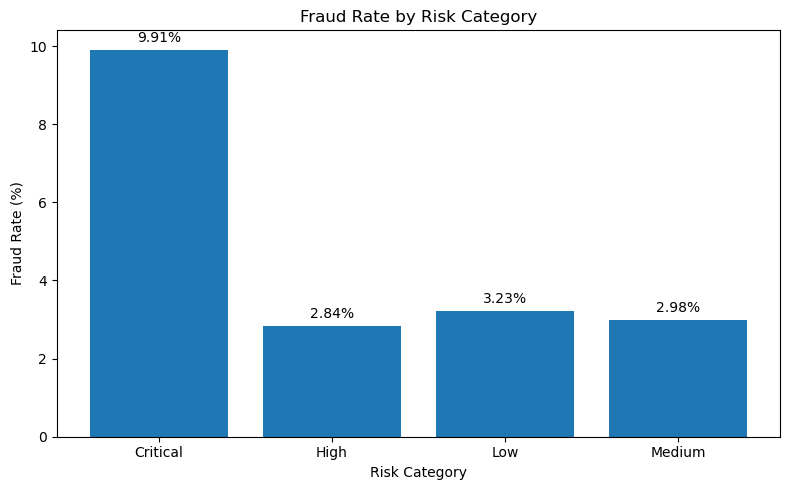

In [6]:
plt.figure(figsize=(8, 5))

plt.bar(
    risk_financial_analysis.index,
    risk_financial_analysis["Fraud_Rate"]
)

plt.title("Fraud Rate by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(risk_financial_analysis["Fraud_Rate"]):
    plt.text(i, value + 0.2, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

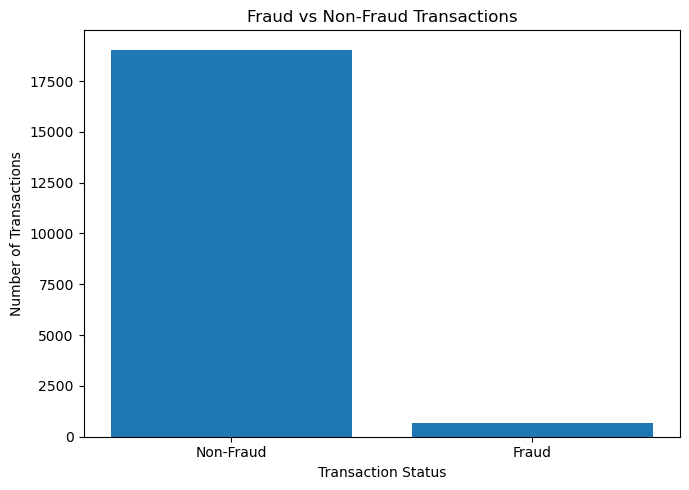

In [5]:
# Fraud distribution Analysis:
fraud_counts = df["Is_Fraud"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Non-Fraud", "Fraud"],
    [fraud_counts[0], fraud_counts[1]]
)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

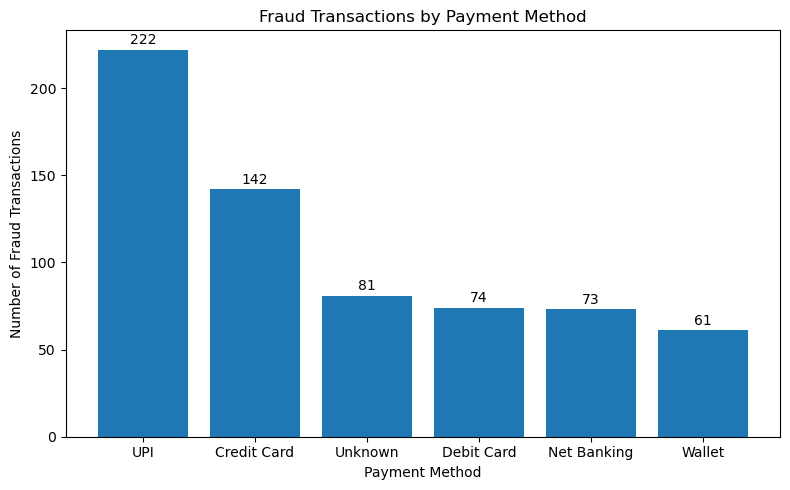

In [7]:
payment_fraud = (
    df[df["Is_Fraud"] == 1]
    .groupby("Payment_Method")["Transaction_ID"]
    .count()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

plt.bar(
    payment_fraud.index,
    payment_fraud.values
)

plt.title("Fraud Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Fraud Transactions")

for i, value in enumerate(payment_fraud.values):
    plt.text(i, value + 3, str(value), ha="center")

plt.tight_layout()
plt.show()

In [7]:
# Velocity Risk Analysis:
velocity_analysis = df.groupby("Velocity_Risk").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

velocity_analysis["Fraud_Rate"] = (
    velocity_analysis["Fraud_Transactions"] /
    velocity_analysis["Transactions"] * 100
)

velocity_analysis.sort_values(
    "Fraud_Rate",
    ascending=False
)

,Transactions,Fraud_Transactions,Fraud_Rate
Velocity_Risk,,,
High,339,59,17.404130
Low,8791,278,3.162325
Medium,2492,76,3.049759
Very Low,8075,240,2.972136


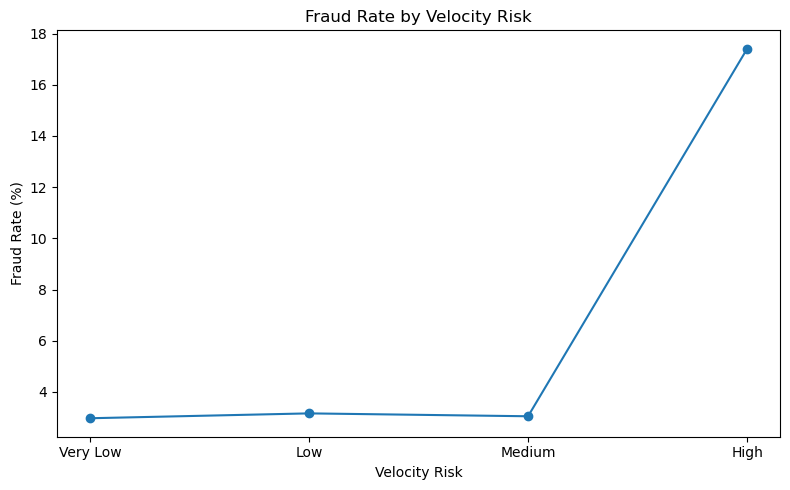

In [8]:
# Fraud Rate by Velocity risk:
velocity_order = ["Very Low", "Low", "Medium", "High"]

velocity_plot = velocity_analysis.reindex(velocity_order)

plt.figure(figsize=(8, 5))

plt.plot(
    velocity_plot.index,
    velocity_plot["Fraud_Rate"],
    marker="o"
)

plt.title("Fraud Rate by Velocity Risk")
plt.xlabel("Velocity Risk")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

In [10]:
city_analysis = (
    df.groupby("City")
    .agg(
        Transactions=("Transaction_ID", "count"),
        Fraud_Transactions=("Is_Fraud", "sum"),
        Fraud_Amount=("Amount", lambda x: x[df.loc[x.index, "Is_Fraud"] == 1].sum())
    )
)

city_analysis["Fraud_Rate"] = (
    city_analysis["Fraud_Transactions"] /
    city_analysis["Transactions"] * 100
)

top_10_cities = city_analysis.sort_values(
    "Fraud_Transactions",
    ascending=False
).head(10)

top_10_cities

,Transactions,Fraud_Transactions,Fraud_Amount,Fraud_Rate
City,,,,
Lucknow,2023,85,1131431.13,4.201681
Ahmedabad,1957,72,1117409.35,3.679101
Pune,1999,68,123805.22,3.401701
Kolkata,1962,65,114096.01,3.312946
Delhi,1983,63,109930.22,3.177005
Hyderabad,2031,63,151086.81,3.101920
Jaipur,1884,63,112734.73,3.343949
Mumbai,1882,61,106769.90,3.241233
Chennai,1929,59,113167.13,3.058580


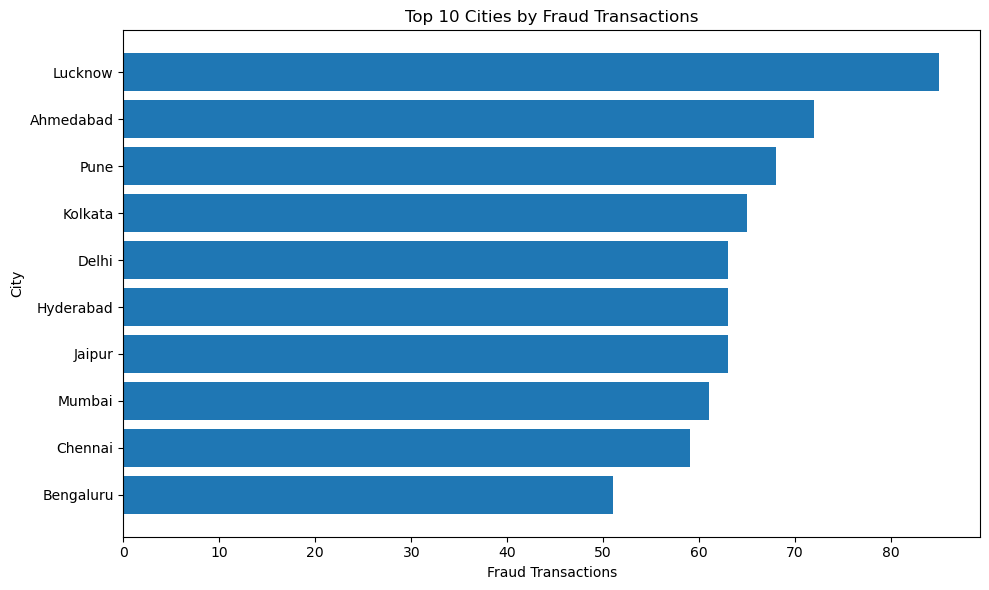

In [11]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_cities.index[::-1],
    top_10_cities["Fraud_Transactions"][::-1]
)

plt.title("Top 10 Cities by Fraud Transactions")
plt.xlabel("Fraud Transactions")
plt.ylabel("City")

plt.tight_layout()
plt.show()

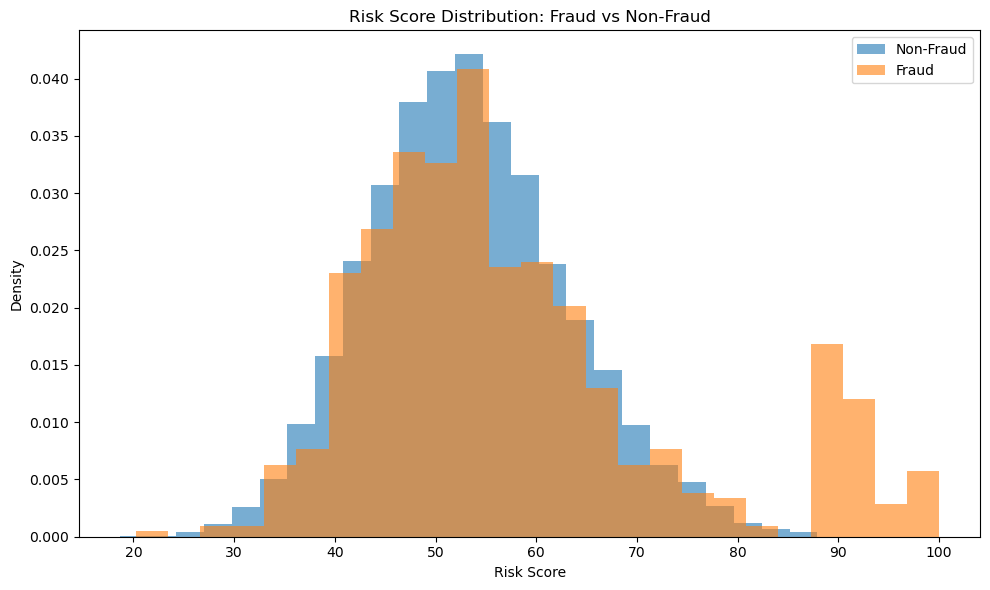

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df[df["Is_Fraud"] == 0]["Risk_Score"],
    bins=25,
    alpha=0.6,
    density=True,
    label="Non-Fraud"
)

plt.hist(
    df[df["Is_Fraud"] == 1]["Risk_Score"],
    bins=25,
    alpha=0.6,
    density=True,
    label="Fraud"
)

plt.title("Risk Score Distribution: Fraud vs Non-Fraud")
plt.xlabel("Risk Score")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
customer_segment_fraud = (
    df.groupby("Customer_Segment")
    .agg(
        Transactions=("Transaction_ID", "count"),
        Fraud_Transactions=("Is_Fraud", "sum")
    )
)

customer_segment_fraud["Fraud_Rate"] = (
    customer_segment_fraud["Fraud_Transactions"]
    / customer_segment_fraud["Transactions"]
    * 100
)

customer_segment_fraud = customer_segment_fraud.sort_values(
    "Fraud_Rate",
    ascending=False
)

customer_segment_fraud

,Transactions,Fraud_Transactions,Fraud_Rate
Customer_Segment,,,
Premium,6530,229,3.506891
New,6556,214,3.264185
Regular,6611,210,3.176524


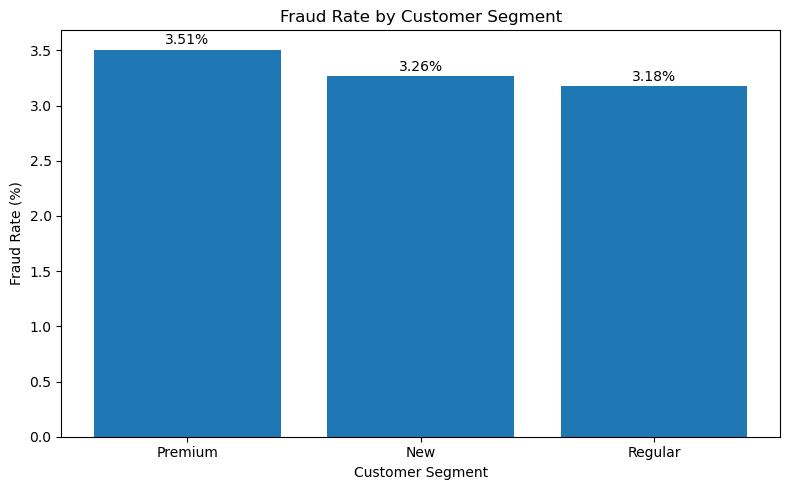

In [9]:
plt.figure(figsize=(8, 5))

plt.bar(
    customer_segment_fraud.index,
    customer_segment_fraud["Fraud_Rate"]
)

plt.title("Fraud Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(customer_segment_fraud["Fraud_Rate"]):
    plt.text(i, value + 0.05, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [17]:
login_international_analysis = df.groupby(
    ["Login_Risk", "International_Transaction"]
).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

login_international_analysis["Fraud_Rate"] = (
    login_international_analysis["Fraud_Transactions"]
    / login_international_analysis["Transactions"] * 100
)

login_international_analysis

Transactions  Fraud_Transactions  \
Login_Risk International_Transaction                                     
High       No                                  272                  21   
           Yes                                  13                   3   
Low        No                                 5702                 179   
           Yes                                 244                  15   
Medium     No                                 1491                  58   
           Yes                                  50                   1   
Unknown    No                                11512                 360   
           Yes                                 413                  16   

                                      Fraud_Rate  
Login_Risk International_Transaction              
High       No                           7.720588  
           Yes                         23.076923  
Low        No                           3.139249  
           Yes                          6.147541  
Medium     No                           3.890007  
           Yes                          2.000000  
Unknown    No                           3.127172  
           Yes                          3.874092

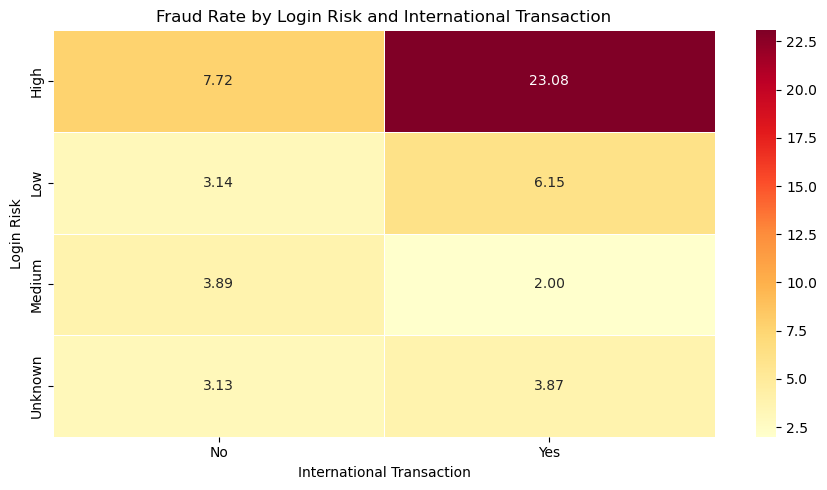

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

login_international_pivot = login_international_analysis[
    "Fraud_Rate"
].unstack()

plt.figure(figsize=(9, 5))

sns.heatmap(
    login_international_pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Fraud Rate by Login Risk and International Transaction")
plt.xlabel("International Transaction")
plt.ylabel("Login Risk")

plt.tight_layout()
plt.show()

In [10]:
amount_analysis = df.groupby("Is_Fraud")["Amount"].agg(
    Count="count",
    Average="mean",
    Minimum="min",
    Maximum="max",
    Total="sum"
)

amount_analysis.index = ["Non-Fraud", "Fraud"]

amount_analysis

,Count,Average,Minimum,Maximum,Total
Non-Fraud,19044,2167.590234,-150.00,999999.99,41279588.42
Fraud,653,7911.525911,52.04,999999.99,5166226.42


<Figure size 800x500 with 0 Axes>

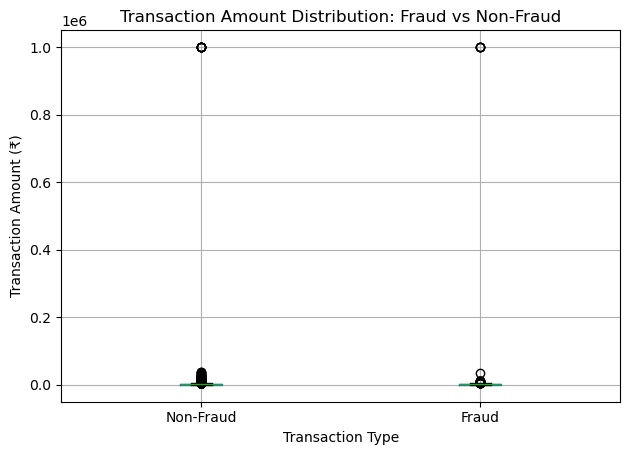

In [12]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="Amount",
    by="Is_Fraud"
)

plt.title("Transaction Amount Distribution: Fraud vs Non-Fraud")
plt.suptitle("")
plt.xlabel("Transaction Type")
plt.ylabel("Transaction Amount (₹)")

plt.xticks([1, 2], ["Non-Fraud", "Fraud"])

plt.tight_layout()
plt.show()

In [14]:
df["Distance_Band"] = pd.cut(
    df["Distance_From_Home_KM"],
    bins=[-1, 5, 20, 50, 100, float("inf")],
    labels=["0-5 KM", "6-20 KM", "21-50 KM", "51-100 KM", "100+ KM"]
)

distance_analysis = df.groupby("Distance_Band", observed=False).agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

distance_analysis["Fraud_Rate"] = (
    distance_analysis["Fraud_Transactions"] /
    distance_analysis["Transactions"] * 100
)

distance_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Distance_Band,,,
0-5 KM,5626,190,3.377177
6-20 KM,1608,54,3.358209
21-50 KM,3298,111,3.365676
51-100 KM,4905,157,3.200815
100+ KM,4260,141,3.309859


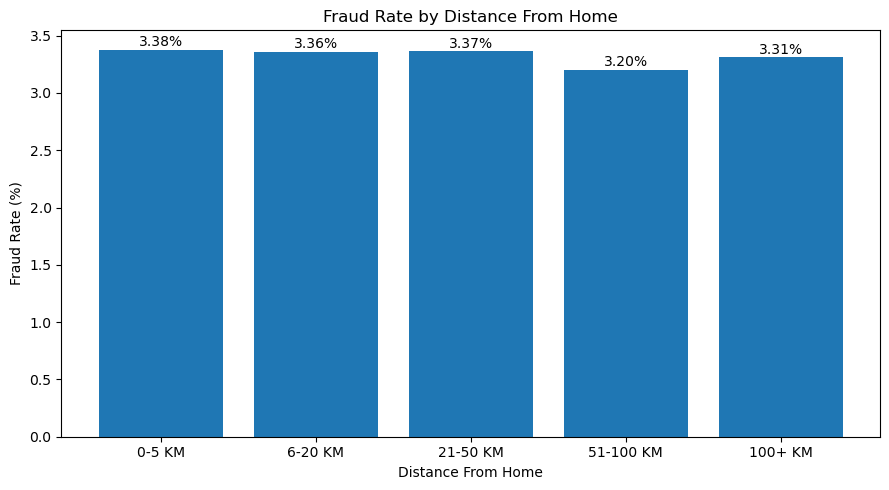

In [15]:
plt.figure(figsize=(9, 5))

plt.bar(
    distance_analysis.index.astype(str),
    distance_analysis["Fraud_Rate"]
)

plt.title("Fraud Rate by Distance From Home")
plt.xlabel("Distance From Home")
plt.ylabel("Fraud Rate (%)")

for i, value in enumerate(distance_analysis["Fraud_Rate"]):
    plt.text(i, value + 0.03, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

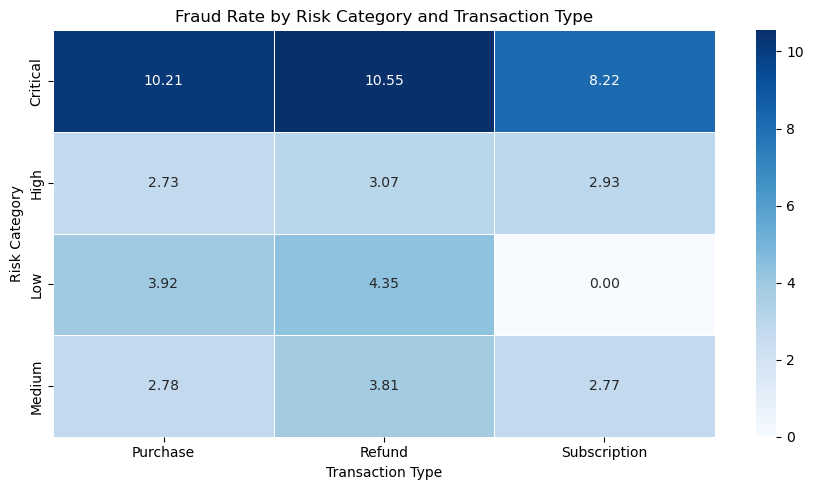

In [5]:
risk_type_pivot = df.pivot_table(
    index="Risk_Category",
    columns="Transaction_Type",
    values="Is_Fraud",
    aggfunc="mean"
) * 100

plt.figure(figsize=(9, 5))

sns.heatmap(
    risk_type_pivot,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    linecolor="white"
)


plt.title("Fraud Rate by Risk Category and Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Risk Category")

plt.tight_layout()
plt.show()

In [6]:
# Fraud rate by transaction hour

hour_analysis = df.groupby("Transaction_Hour").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

hour_analysis["Fraud_Rate"] = (
    hour_analysis["Fraud_Transactions"]
    / hour_analysis["Transactions"]
    * 100
)

hour_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Transaction_Hour,,,
0,799,29,3.629537
1,816,37,4.534314
2,838,41,4.892601
3,812,32,3.940887
4,792,35,4.419192
5,837,30,3.584229
6,839,29,3.456496
7,817,29,3.549572
8,770,21,2.727273


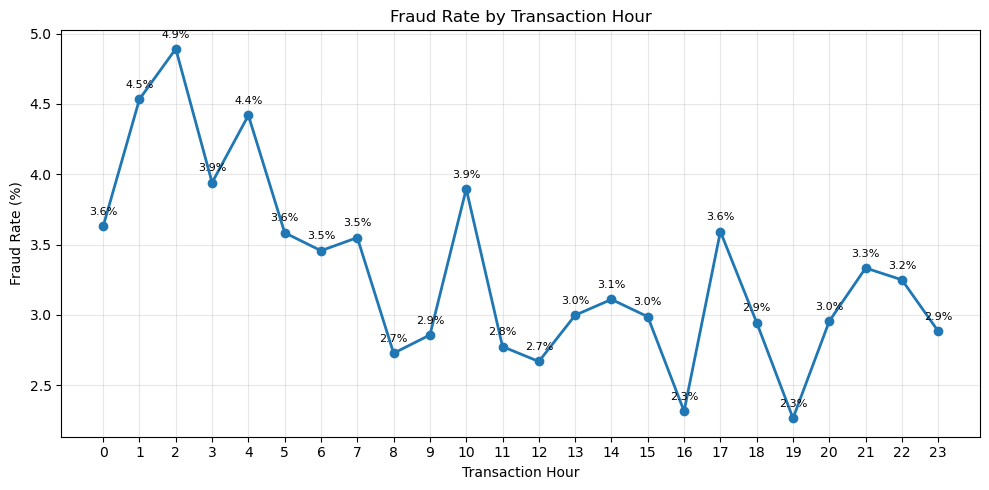

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(
    hour_analysis.index,
    hour_analysis["Fraud_Rate"],
    marker="o",
    linewidth=2
)

plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

# Add values to the points
for hour, rate in hour_analysis["Fraud_Rate"].items():
    plt.text(
        hour,
        rate + 0.08,
        f"{rate:.1f}%",
        ha="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [8]:
device_fraud = (
    df[df["Is_Fraud"] == 1]
    ["Device_Type"]
    .value_counts()
)

device_fraud

Device_Type
Windows    169
Android    157
iOS        145
MacOS       99
Unknown     83
Name: count, dtype: int64

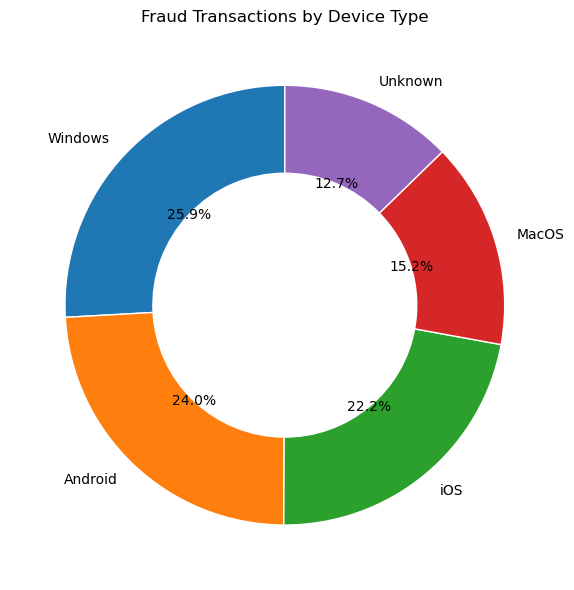

In [9]:
plt.figure(figsize=(8, 6))

plt.pie(
    device_fraud.values,
    labels=device_fraud.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.4, edgecolor="white")
)

plt.title("Fraud Transactions by Device Type")
plt.tight_layout()
plt.show()

In [10]:
international_fraud = (
    df[df["Is_Fraud"] == 1]
    ["International_Transaction"]
    .value_counts()
)

international_fraud

International_Transaction
No     618
Yes     35
Name: count, dtype: int64

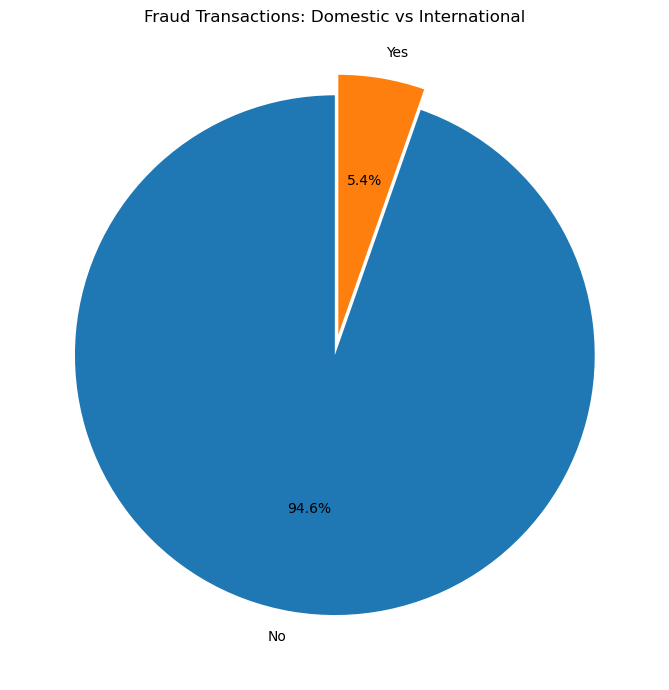

In [11]:
plt.figure(figsize=(7, 7))

plt.pie(
    international_fraud.values,
    labels=international_fraud.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0, 0.08]
)

plt.title("Fraud Transactions: Domestic vs International")
plt.tight_layout()
plt.show()

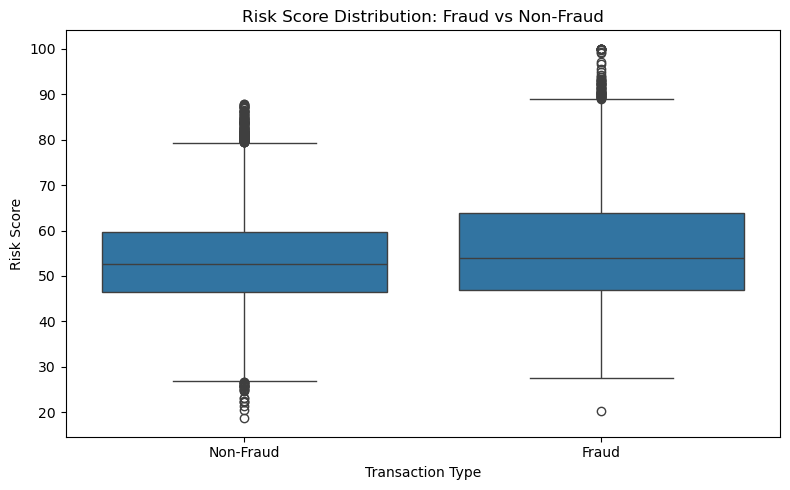

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Is_Fraud",
    y="Risk_Score"
)

plt.xticks([0, 1], ["Non-Fraud", "Fraud"])
plt.xlabel("Transaction Type")
plt.ylabel("Risk Score")
plt.title("Risk Score Distribution: Fraud vs Non-Fraud")

plt.tight_layout()
plt.show()

In [14]:
failed_login_analysis = df.groupby("Failed_Login_Attempts").agg(
    Transactions=("Transaction_ID", "count"),
    Fraud_Transactions=("Is_Fraud", "sum")
)

failed_login_analysis["Fraud_Rate"] = (
    failed_login_analysis["Fraud_Transactions"]
    / failed_login_analysis["Transactions"]
    * 100
)

failed_login_analysis

,Transactions,Fraud_Transactions,Fraud_Rate
Failed_Login_Attempts,,,
0,11925,376,3.153040
1,5946,194,3.262698
2,1541,59,3.828683
3,240,15,6.250000
4,41,8,19.512195
5,4,1,25.000000


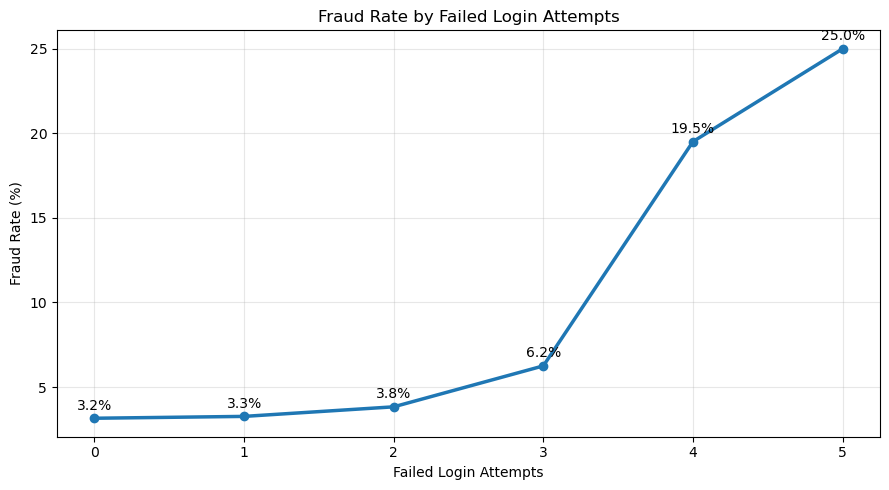

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    failed_login_analysis.index,
    failed_login_analysis["Fraud_Rate"],
    marker="o",
    linewidth=2.5
)

for x, y in zip(
    failed_login_analysis.index,
    failed_login_analysis["Fraud_Rate"]
):
    plt.text(
        x,
        y + 0.5,
        f"{y:.1f}%",
        ha="center"
    )

plt.title("Fraud Rate by Failed Login Attempts")
plt.xlabel("Failed Login Attempts")
plt.ylabel("Fraud Rate (%)")
plt.xticks(failed_login_analysis.index)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
transaction_type_fraud = (
    df[df["Is_Fraud"] == 1]["Transaction_Type"]
    .value_counts()
)

transaction_type_fraud

Transaction_Type
Purchase        380
Refund          149
Subscription    124
Name: count, dtype: int64

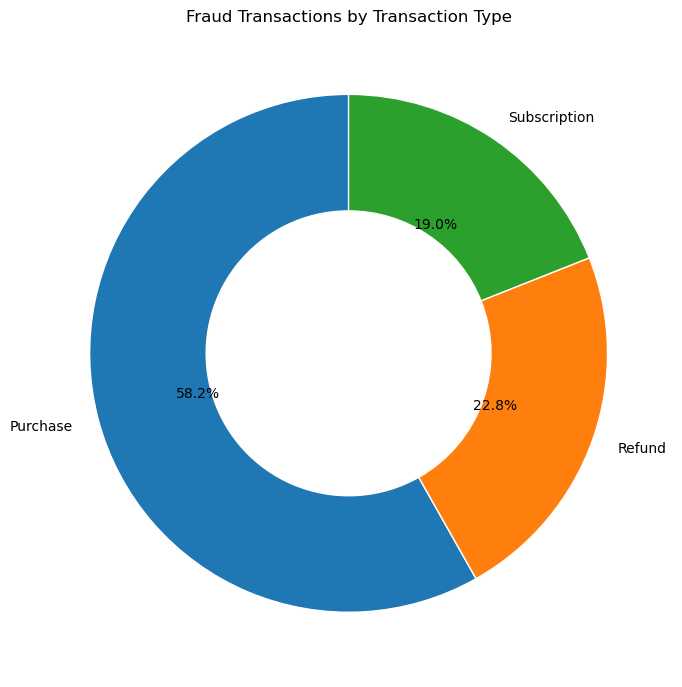

In [17]:
plt.figure(figsize=(7, 7))

plt.pie(
    transaction_type_fraud.values,
    labels=transaction_type_fraud.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.45, edgecolor="white")
)

plt.title("Fraud Transactions by Transaction Type")

plt.tight_layout()
plt.show()

In [18]:
account_age_fraud = (
    df[df["Is_Fraud"] == 1]["Account_Age_Years"]
    .value_counts()
    .sort_index()
)

account_age_fraud

Account_Age_Years
1    103
2    105
3    117
4    111
5    119
6     98
Name: count, dtype: int64

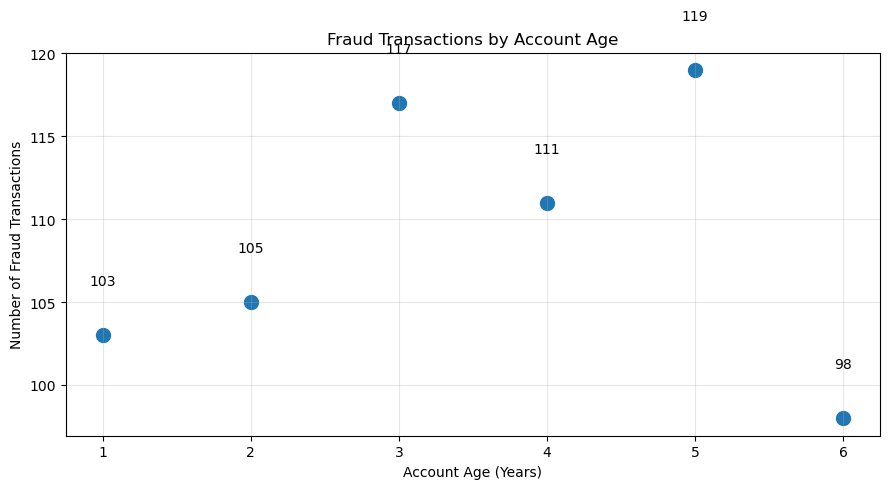

In [19]:
plt.figure(figsize=(9, 5))

plt.scatter(
    account_age_fraud.index,
    account_age_fraud.values,
    s=100
)

for x, y in zip(account_age_fraud.index, account_age_fraud.values):
    plt.text(
        x,
        y + 3,
        str(y),
        ha="center"
    )

plt.title("Fraud Transactions by Account Age")
plt.xlabel("Account Age (Years)")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(account_age_fraud.index)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
login_risk_fraud = (
    df[df["Is_Fraud"] == 1]["Login_Risk"]
    .value_counts()
)

login_risk_fraud

Login_Risk
Unknown    376
Low        194
Medium      59
High        24
Name: count, dtype: int64

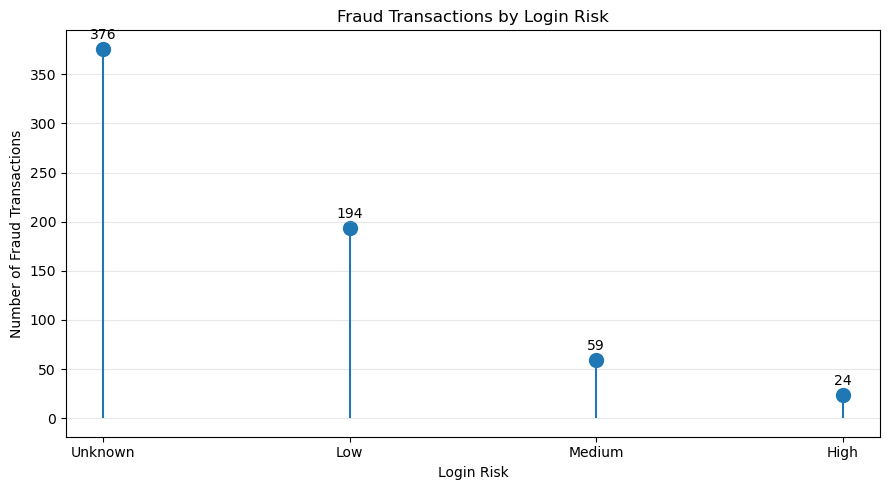

In [21]:
plt.figure(figsize=(9, 5))

x = range(len(login_risk_fraud))

plt.stem(
    x,
    login_risk_fraud.values,
    basefmt=" "
)

plt.scatter(
    x,
    login_risk_fraud.values,
    s=100
)

for i, value in enumerate(login_risk_fraud.values):
    plt.text(
        i,
        value + 10,
        str(value),
        ha="center"
    )

plt.title("Fraud Transactions by Login Risk")
plt.xlabel("Login Risk")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(
    x,
    login_risk_fraud.index
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
payment_fraud = (
    df[df["Is_Fraud"] == 1]["Payment_Method"]
    .value_counts()
)

payment_fraud

Payment_Method
UPI            222
Credit Card    142
Unknown         81
Debit Card      74
Net Banking     73
Wallet          61
Name: count, dtype: int64

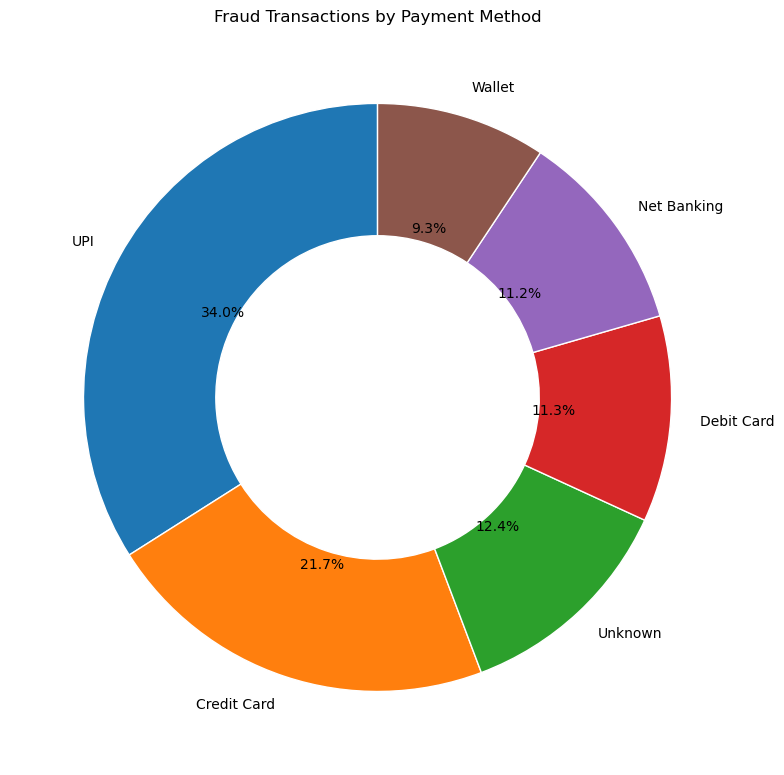

In [23]:
plt.figure(figsize=(8, 8))

plt.pie(
    payment_fraud.values,
    labels=payment_fraud.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.45, edgecolor='white')
)

plt.title("Fraud Transactions by Payment Method")
plt.tight_layout()
plt.show()

In [24]:
customer_segment_fraud = (
    df[df["Is_Fraud"] == 1]["Customer_Segment"]
    .value_counts()
    .sort_values()
)

customer_segment_fraud

Customer_Segment
Regular    210
New        214
Premium    229
Name: count, dtype: int64

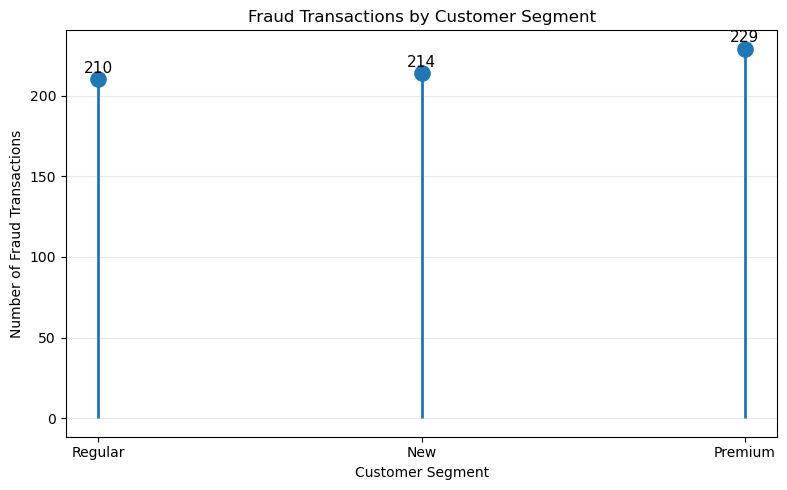

In [25]:
plt.figure(figsize=(8, 5))

x = customer_segment_fraud.index
y = customer_segment_fraud.values

plt.vlines(x, 0, y, linewidth=2)
plt.scatter(x, y, s=120)

for i, value in enumerate(y):
    plt.text(i, value + 4, str(value), ha='center', fontsize=11)

plt.title("Fraud Transactions by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Fraud Transactions")
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
# Convert transaction date to datetime
df["Transaction_DateTime"] = pd.to_datetime(df["Transaction_DateTime"])

# Calculate monthly fraud amount
monthly_fraud = (
    df[df["Is_Fraud"] == 1]
    .set_index("Transaction_DateTime")
    .resample("M")["Amount"]
    .sum()
)

monthly_fraud

C:\Users\OMAIR\AppData\Local\Temp\ipykernel_16676\1519683386.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample("M")["Amount"]


Transaction_DateTime
2025-01-31     104357.48
2025-02-28      71750.40
2025-03-31    2091614.01
2025-04-30      99038.70
2025-05-31      71986.42
2025-06-30      75309.85
2025-07-31    1149494.10
2025-08-31    1092933.13
2025-09-30     103105.44
2025-10-31      99403.36
2025-11-30     110376.24
2025-12-31      96857.29
Freq: ME, Name: Amount, dtype: float64

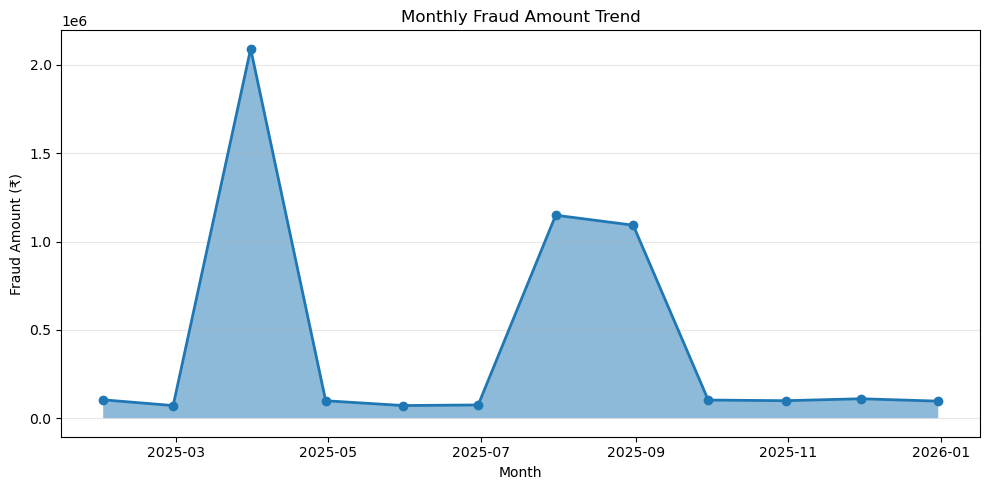

In [28]:
plt.figure(figsize=(10, 5))

plt.fill_between(
    monthly_fraud.index,
    monthly_fraud.values,
    alpha=0.5
)

plt.plot(
    monthly_fraud.index,
    monthly_fraud.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Fraud Amount Trend")
plt.xlabel("Month")
plt.ylabel("Fraud Amount (₹)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
df.columns.tolist()

['Transaction_ID',
 'Customer_ID',
 'Transaction_DateTime',
 'Amount',
 'Currency',
 'Payment_Method',
 'Merchant_Category',
 'Transaction_Type',
 'City',
 'Country',
 'Device_Type',
 'Browser',
 'Transactions_Last_24H',
 'Distance_From_Home_KM',
 'Failed_Login_Attempts',
 'Account_Age_Years',
 'Customer_Segment',
 'Customer_Email',
 'Customer_Phone',
 'Is_Fraud',
 'Risk_Score',
 'Transaction_Status',
 'International_Transaction',
 'Transaction_Hour',
 'Day_of_Week',
 'Weekend_Flag',
 'Account_Age_Months',
 'Transaction_Amount_Band',
 'Velocity_Risk',
 'Location_Risk',
 'Login_Risk',
 'Risk_Category',
 'Anomaly_Flag',
 'Card_Transaction_Flag',
 'Data_Quality_Flag',
 'Amount_Quality']

In [31]:
numeric_cols = [
    "Amount",
    "Transactions_Last_24H",
    "Distance_From_Home_KM",
    "Failed_Login_Attempts",
    "Account_Age_Years",
    "Risk_Score",
    "Transaction_Hour",
    "Account_Age_Months",
    "Is_Fraud"
]

correlation = df[numeric_cols].corr()

correlation

,Amount,Transactions_Last_24H,Distance_From_Home_KM,Failed_Login_Attempts,Account_Age_Years,Risk_Score,Transaction_Hour,Account_Age_Months,Is_Fraud
Amount,1.000000,0.023222,0.004905,-0.003091,0.001637,0.069180,-0.002143,0.001637,0.043410
Transactions_Last_24H,0.023222,1.000000,-0.002618,0.005767,0.006888,0.098782,-0.001469,0.006888,0.045509
Distance_From_Home_KM,0.004905,-0.002618,1.000000,-0.004074,0.002727,0.008080,0.001372,0.002727,-0.004892
Failed_Login_Attempts,-0.003091,0.005767,-0.004074,1.000000,-0.004895,0.077679,0.002156,-0.004895,0.025739
Account_Age_Years,0.001637,0.006888,0.002727,-0.004895,1.000000,0.005607,-0.000312,1.000000,0.002471
Risk_Score,0.069180,0.098782,0.008080,0.077679,0.005607,1.000000,-0.340305,0.005607,0.081029
Transaction_Hour,-0.002143,-0.001469,0.001372,0.002156,-0.000312,-0.340305,1.000000,-0.000312,-0.023812
Account_Age_Months,0.001637,0.006888,0.002727,-0.004895,1.000000,0.005607,-0.000312,1.000000,0.002471
Is_Fraud,0.043410,0.045509,-0.004892,0.025739,0.002471,0.081029,-0.023812,0.002471,1.000000


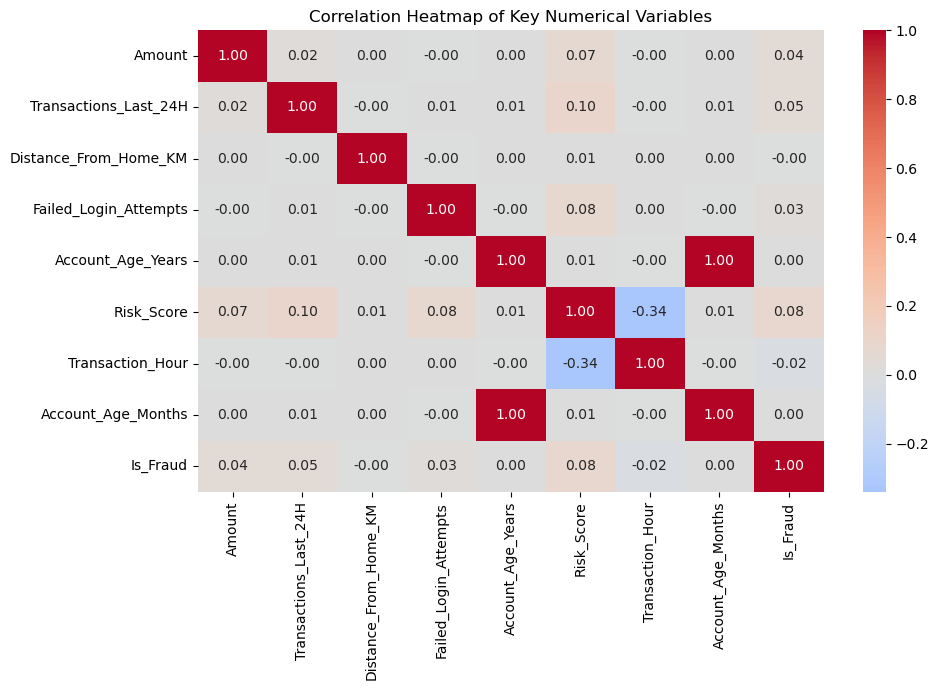

In [32]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Key Numerical Variables")
plt.tight_layout()
plt.show()

In [4]:
fraud_summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Fraud Transactions",
        "Fraud Rate (%)",
        "Total Fraud Amount (₹)",
        "Average Fraud Transaction (₹)",
        "Maximum Fraud Transaction (₹)"
    ],
    "Value": [
        len(df),
        df["Is_Fraud"].sum(),
        df["Is_Fraud"].mean() * 100,
        df.loc[df["Is_Fraud"] == 1, "Amount"].sum(),
        df.loc[df["Is_Fraud"] == 1, "Amount"].mean(),
        df.loc[df["Is_Fraud"] == 1, "Amount"].max()
    ]
})

# Format values for easy reading
fraud_summary["Value"] = [
    f"{fraud_summary.loc[0, 'Value']:,.0f}",
    f"{fraud_summary.loc[1, 'Value']:,.0f}",
    f"{fraud_summary.loc[2, 'Value']:.2f}%",
    f"₹{fraud_summary.loc[3, 'Value']:,.2f}",
    f"₹{fraud_summary.loc[4, 'Value']:,.2f}",
    f"₹{fraud_summary.loc[5, 'Value']:,.2f}"
]

fraud_summary

,Metric,Value
0,Total Transactions,"19,697"
1,Fraud Transactions,653
2,Fraud Rate (%),3.32%
3,Total Fraud Amount (₹),"₹5,166,226.42"
4,Average Fraud Transaction (₹),"₹7,911.53"
5,Maximum Fraud Transaction (₹),"₹999,999.99"


Final Findings :

The Python analysis identified several important patterns in online transaction fraud. Out of 19,697 analyzed transactions, 653 were classified as fraudulent, resulting in an overall fraud rate of 3.32%. The total value associated with fraudulent transactions was approximately ₹5.17 million, with an average fraudulent transaction value of approximately ₹7,912.

Fraud rates increased substantially as the number of failed login attempts increased, reaching 25% for transactions with five failed login attempts. Fraudulent transactions were distributed across different payment methods, transaction types, customer segments, device types and login-risk categories. Purchase transactions accounted for the largest share of fraudulent transactions, while UPI recorded the highest number of fraudulent transactions among the payment methods analyzed.

The analysis also showed variation in fraud activity across transaction hours and months. The correlation analysis indicated that most individual numerical variables had weak correlations with fraud, suggesting that fraud patterns are influenced by multiple factors rather than one numerical variable alone.

Overall, the Python analysis provided statistical insights into fraud frequency, transaction values, behavioural patterns, risk indicators, categorical distributions and relationships among numerical variables.